In [9]:
import statsmodels.api as sm
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
macro_econ_data = sm.datasets.macrodata.load_pandas().data
macro_econ_data.head()

,year,quarter,realgdp,realcons,realinv,realgovt,realdpi,cpi,m1,tbilrate,unemp,pop,infl,realint
0,1959.0,1.0,2710.349,1707.4,286.898,470.045,1886.9,28.98,139.7,2.82,5.8,177.146,0.00,0.00
1,1959.0,2.0,2778.801,1733.7,310.859,481.301,1919.7,29.15,141.7,3.08,5.1,177.830,2.34,0.74
2,1959.0,3.0,2775.488,1751.8,289.226,491.260,1916.4,29.35,140.5,3.82,5.3,178.657,2.74,1.09
3,1959.0,4.0,2785.204,1753.7,299.356,484.052,1931.3,29.37,140.0,4.33,5.6,179.386,0.27,4.06
4,1960.0,1.0,2847.699,1770.5,331.722,462.199,1955.5,29.54,139.6,3.50,5.2,180.007,2.31,1.19


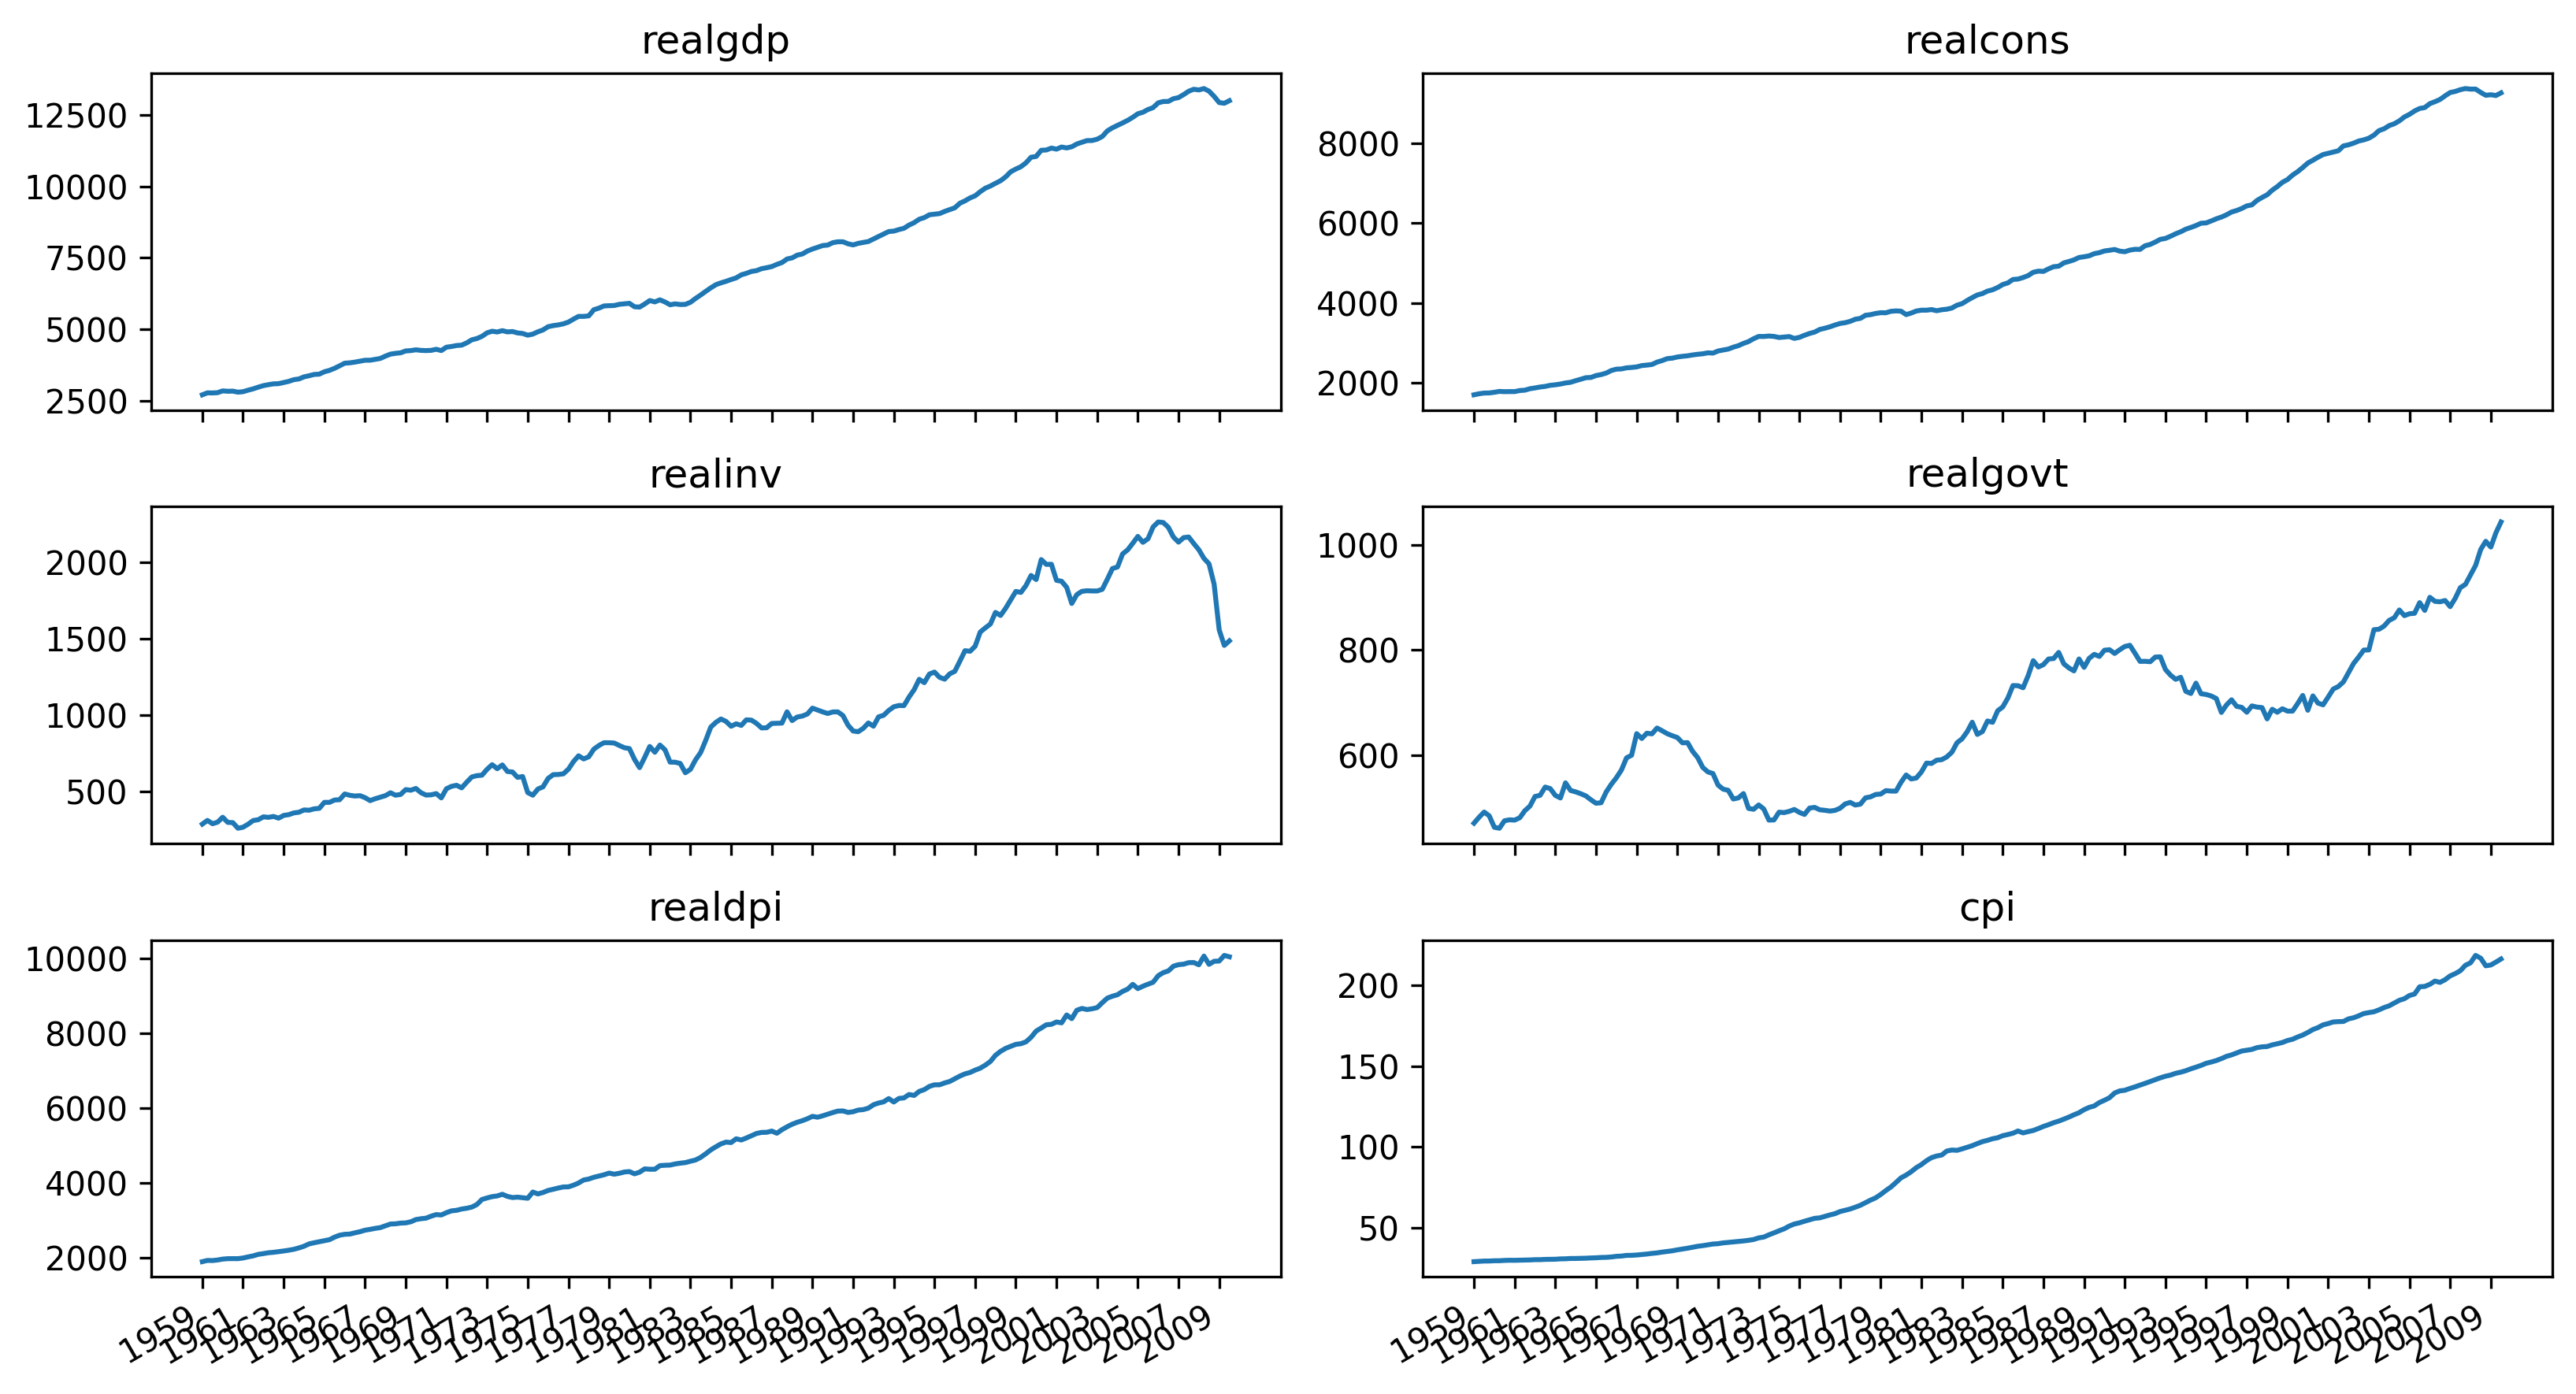

In [10]:
fig, axes = plt.subplots(nrows=3, ncols=2, dpi=300, figsize=(11,6))
for i, ax in enumerate(axes.flatten()[:6]):
    data = macro_econ_data[macro_econ_data.columns[i+2]]
    ax.plot(data)
    ax.set_title(macro_econ_data.columns[i+2])
    plt.setp(axes, xticks=np.arange(0, 208, 8), xticklabels=np.arange(1959, 2010, 2))
    fig.autofmt_xdate()
    plt.tight_layout()

In [11]:
target = macro_econ_data['realgdp']
exog = macro_econ_data[['realcons', 'realinv', 'realgovt', 'realdpi', 'cpi']]

In [13]:
from statsmodels.tsa.stattools import adfuller
d = 1
adf = adfuller(target)
while adf[2] > 0.05:
	adf = adfuller(np.diff(target, d))
	d += 1
print(f'ADF: {adf[:2]}, d: {d}')

ADF: (-127.73769860235254, 0.0), d: 197


In [14]:
from typing import Union
from tqdm import tqdm_notebook
from statsmodels.tsa.statespace.sarimax import SARIMAX

def optimize_SARIMAX(endog: Union[pd.Series, list], exog: Union[pd.Series, list], order_list: list, d: int, D: int, s: int) -> pd.DataFrame:
    results = []
    for order in tqdm_notebook(order_list):
        try:
            model = SARIMAX(
                endog,
                exog,
				order=(order[0], d, order[1]),
				seasonal_order=(order[2], D, order[3], s),
				simple_differencing=False).fit(disp=False)
        except:
            continue
        aic = model.aic
        results.append([order, aic])
    result_df = pd.DataFrame(results)
    result_df.columns = ['(p,q,P,Q)', 'AIC']
    #Sort in ascending order, lower AIC is better
    result_df = result_df.sort_values(by='AIC', ascending=True).reset_index(drop=True)
    return result_df


In [15]:
from itertools import product
p = range(0, 4, 1)
d=1
q = range(0, 4, 1)
P = range(0, 4, 1) 
D=0
Q = range(0, 4, 1) 
s=4
parameters = list(product(p, q, P, Q))

In [16]:
target_train = target[:200]
exog_train = exog[:200]
result_df = optimize_SARIMAX(target_train, exog_train, parameters, d, D, s)
result_df

/var/folders/hv/y00c8cl91z34xlwn9xbh5cfr0000gn/T/ipykernel_55883/2407559039.py:7: TqdmDeprecationWarning: This function will be removed in tqdm==5.0.0
Please use `tqdm.notebook.tqdm` instead of `tqdm.tqdm_notebook`
  for order in tqdm_notebook(order_list):


  0%|          | 0/256 [00:00<?, ?it/s]

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: M

,"(p,q,P,Q)",AIC
0,"(3, 3, 0, 0)",1742.840942
1,"(3, 3, 1, 0)",1744.964600
2,"(3, 3, 0, 1)",1744.996594
3,"(2, 2, 0, 0)",1745.432304
4,"(2, 2, 0, 1)",1745.806696
...,...,...
251,"(0, 2, 0, 0)",1761.579044
252,"(0, 3, 0, 0)",1762.317095
253,"(0, 0, 0, 0)",1764.754980
254,"(1, 0, 0, 0)",1765.379412


In [17]:
arimax_model = SARIMAX(target_train, exog_train, order=(3, 1, 3), seasonal_order=(0, 0, 0, 4), simple_differencing=False)
arimax_fit = arimax_model.fit(disp=False)
arimax_fit.summary()

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                realgdp   No. Observations:                  200
Model:               SARIMAX(3, 1, 3)   Log Likelihood                -859.420
Date:                Mon, 14 Jul 2025   AIC                           1742.841
Time:                        16:44:58   BIC                           1782.361
Sample:                             0   HQIC                          1758.836
                                - 200                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
realcons       0.9663      0.045     21.625      0.000       0.879       1.054
realinv        1.0136      0.033     30.862      0.000       0.949       1.078
realgovt       0.7280      0.127      5.737      0.000       0.479       0.977
realdpi        0.0092      0.025      0.372      0.710      -0.039       0.058
cpi            5.8672      1.311      4.476      0.000       3.298       8.436
ar.L1          1.0658      0.395      2.697      0.007       0.291       1.840
ar.L2          0.4907      0.696      0.706      0.480      -0.872       1.854
ar.L3         -0.6740      0.334     -2.016      0.044      -1.329      -0.019
ma.L1         -1.1037      0.427     -2.586      0.010      -1.940      -0.267
ma.L2         -0.3205      0.761     -0.421      0.674      -1.812       1.171
ma.L3          0.6461      0.400      1.614      0.106      -0.138       1.430
sigma2       329.6156     30.495     10.809      0.000     269.847     389.384
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):                13.41
Prob(Q):                              0.95   Prob(JB):                         0.00
Heteroskedasticity (H):               3.56   Skew:                             0.32
Prob(H) (two-sided):                  0.00   Kurtosis:                         4.10
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

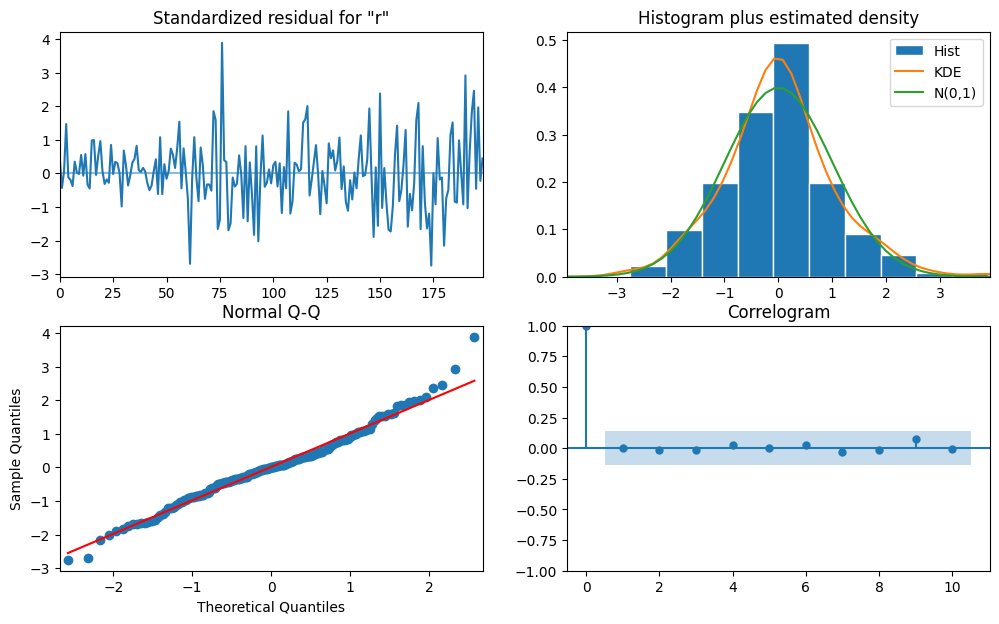

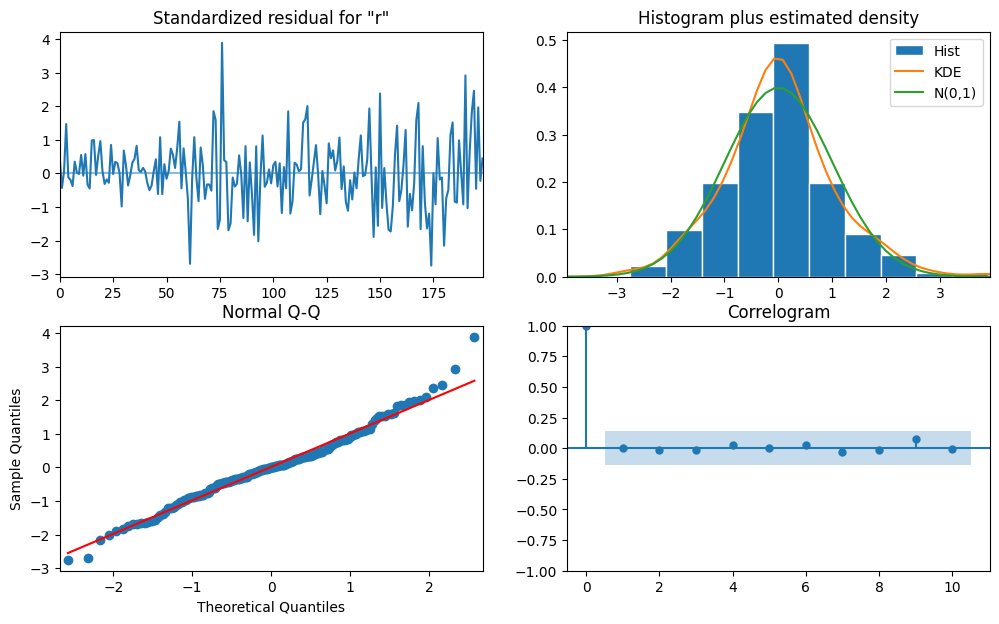

In [18]:
arimax_fit.plot_diagnostics(figsize=(12, 7))

In [19]:
forcasts = arimax_fit.get_prediction(exog=exog[200:203]).predicted_mean